# Week 3 - Thursday: RandomizedSearchCV + Reading the Tuning Results
Dataset: **Breast Cancer** (built into scikit-learn), same split as Wednesday.

Plan for today:
1. Compare **GridSearchCV** and **RandomizedSearchCV** on the same classifier (score and runtime)
2. **Visualise the tuning** with a heatmap of CV score
3. Tune a second and third classifier and collect everything in **one table**
4. Check the results honestly (gain vs spread, edge of the grid) and write the explanation

## Grid vs Random
- **GridSearchCV** tries every combination. Exhaustive, but the cost explodes as you add parameters or values.
- **RandomizedSearchCV** samples `n_iter` random combinations from lists or **distributions** (for example `randint(1, 30)` for integers, `loguniform(1e-3, 1e3)` for scales like `C`). You choose the budget, and wide ranges are covered cheaply.
- Random search is often almost as good as grid search for a fraction of the time, because usually only a few hyperparameters really matter.

## 1. Imports, data and the same split as Wednesday

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, loguniform

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 2. Grid vs Random on a Decision Tree
A Decision Tree has several hyperparameters, so a full grid gets large quickly. We search the **same space** two ways.

In [ ]:
tree = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE))

# Full grid
tree_grid = {
    "model__max_depth": list(range(1, 16)),
    "model__min_samples_leaf": list(range(1, 9)),
    "model__min_samples_split": [2, 5, 10],
    "model__criterion": ["gini", "entropy"],
}
n_grid = 15 * 8 * 3 * 2
print("Grid combinations:", n_grid, " -> fits:", n_grid * 5)
print("The grid search may take about a minute, please wait...")

t0 = time.time()
grid_search = GridSearchCV(tree, tree_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train, y_train)
grid_time = time.time() - t0

# Random search over the same ranges, 50 samples
N_ITER = 50
tree_dist = {
    "model__max_depth": randint(1, 16),
    "model__min_samples_leaf": randint(1, 9),
    "model__min_samples_split": [2, 5, 10],
    "model__criterion": ["gini", "entropy"],
}
t0 = time.time()
rand_search = RandomizedSearchCV(tree, tree_dist, n_iter=N_ITER, cv=cv, scoring="accuracy",
                                 n_jobs=-1, random_state=RANDOM_STATE)
rand_search.fit(X_train, y_train)
rand_time = time.time() - t0

print("Done.")

Grid combinations: 720  -> fits: 3600
The grid search may take about a minute, please wait...


In [ ]:
compare = pd.DataFrame({
    "combinations_tried": [n_grid, N_ITER],
    "search_time_s": [grid_time, rand_time],
    "best_cv_score": [grid_search.best_score_, rand_search.best_score_],
    "cv_std_of_best": [grid_search.cv_results_["std_test_score"][grid_search.best_index_],
                       rand_search.cv_results_["std_test_score"][rand_search.best_index_]],
    "test_accuracy": [accuracy_score(y_test, grid_search.predict(X_test)),
                      accuracy_score(y_test, rand_search.predict(X_test))],
}, index=["GridSearchCV", "RandomizedSearchCV"]).round(4)
compare

,combinations_tried,search_time_s,best_cv_score,cv_std_of_best,test_accuracy
GridSearchCV,720,124.4821,0.9385,0.0192,0.9035
RandomizedSearchCV,50,1.2652,0.9341,0.0139,0.9123


In [ ]:
print("Grid best  :", grid_search.best_params_)
print("Random best:", rand_search.best_params_)
print("Speed-up of random over grid: about", round(grid_time / rand_time, 1), "x")

Grid best  : {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Random best: {'model__criterion': 'gini', 'model__max_depth': 12, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Speed-up of random over grid: about 98.4 x


**Look at:** does random search reach almost the same CV score as grid search? Is the gap smaller than `cv_std_of_best`? If yes, the two are effectively tied, and random search got there with far fewer combinations.

## 3. Visualise the tuning: heatmap of CV score

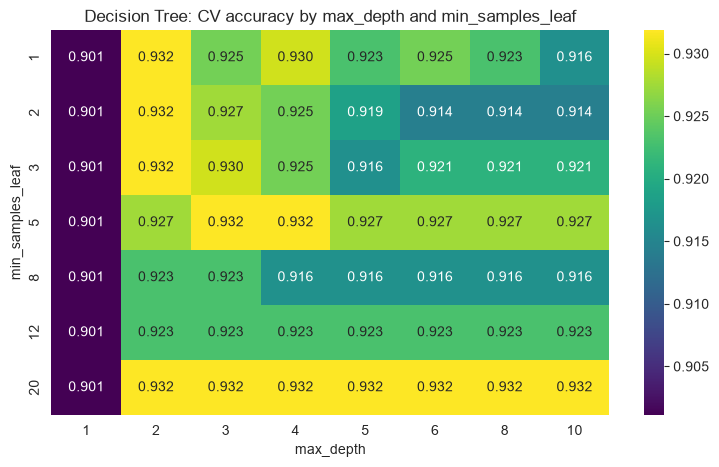

In [ ]:
# A small 2-parameter grid so the heatmap is easy to read
heat_grid = {
    "model__max_depth": [1, 2, 3, 4, 5, 6, 8, 10],
    "model__min_samples_leaf": [1, 2, 3, 5, 8, 12, 20],
}
heat_search = GridSearchCV(tree, heat_grid, cv=cv, scoring="accuracy", n_jobs=-1)
heat_search.fit(X_train, y_train)

res = pd.DataFrame(heat_search.cv_results_)
pivot = res.pivot(index="param_model__min_samples_leaf",
                  columns="param_model__max_depth", values="mean_test_score")
pivot.index = pivot.index.astype(int); pivot.columns = pivot.columns.astype(int)
pivot = pivot.sort_index().sort_index(axis=1)

plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Decision Tree: CV accuracy by max_depth and min_samples_leaf")
plt.xlabel("max_depth"); plt.ylabel("min_samples_leaf")
plt.show()

**Reading the heatmap:** look for a bright region rather than one single bright cell. If many neighbouring cells score almost the same, the exact best value does not matter much. Very low `max_depth` (1 or 2) underfits, very high values can overfit.

## 4. Tune a second and third classifier (RandomizedSearchCV)

In [ ]:
searches = {}

# kNN
t0 = time.time()
s = RandomizedSearchCV(
    make_pipe(KNeighborsClassifier()),
    {"model__n_neighbors": randint(1, 51),
     "model__weights": ["uniform", "distance"],
     "model__metric": ["euclidean", "manhattan"]},
    n_iter=40, cv=cv, scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE)
s.fit(X_train, y_train)
searches["kNN"] = (s, time.time() - t0, make_pipe(KNeighborsClassifier()))

# SVM (RBF): C and gamma are scales, so sample them on a log scale
t0 = time.time()
s = RandomizedSearchCV(
    make_pipe(SVC()),
    {"model__C": loguniform(1e-2, 1e3),
     "model__gamma": loguniform(1e-4, 1e0)},
    n_iter=40, cv=cv, scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE)
s.fit(X_train, y_train)
searches["SVM (RBF)"] = (s, time.time() - t0, make_pipe(SVC()))

# Decision Tree: reuse the random search from section 2
searches["Decision Tree"] = (rand_search, rand_time, tree)

for name, (s, t, _) in searches.items():
    print(f"{name:14s} best CV = {s.best_score_:.4f}   time = {t:.1f}s")
    print("   ", s.best_params_)

kNN            best CV = 0.9714   time = 1.0s
    {'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'uniform'}
SVM (RBF)      best CV = 0.9758   time = 1.0s
    {'model__C': np.float64(26.373339933815235), 'model__gamma': np.float64(0.005762487216478602)}
Decision Tree  best CV = 0.9341   time = 1.3s
    {'model__criterion': 'gini', 'model__max_depth': 12, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}


## 5. One results table

In [ ]:
rows = []
for name, (s, t, default_pipe) in searches.items():
    default_cv = cross_val_score(default_pipe, X_train, y_train, cv=cv).mean()
    default_pipe.fit(X_train, y_train)
    best_idx = s.best_index_
    rows.append({
        "model": name,
        "default_cv": default_cv,
        "tuned_cv": s.best_score_,
        "cv_gain": s.best_score_ - default_cv,
        "cv_std": s.cv_results_["std_test_score"][best_idx],
        "default_test": accuracy_score(y_test, default_pipe.predict(X_test)),
        "tuned_test": accuracy_score(y_test, s.predict(X_test)),
        "malignant_recall": recall_score(y_test, s.predict(X_test), pos_label=0),
        "search_time_s": t,
    })
table = pd.DataFrame(rows).set_index("model")
table.round(4)

,default_cv,tuned_cv,cv_gain,cv_std,default_test,tuned_test,malignant_recall,search_time_s
model,,,,,,,,
kNN,0.9626,0.9714,0.0088,0.0132,0.9561,0.9649,0.9286,0.9990
SVM (RBF),0.9692,0.9758,0.0066,0.0108,0.9825,0.9825,0.9762,1.0106
Decision Tree,0.9165,0.9341,0.0176,0.0139,0.9123,0.9123,0.9048,1.2652


In [ ]:
# Best parameters in one place
pd.Series({name: s.best_params_ for name, (s, _, _) in searches.items()})

kNN              {'model__metric': 'manhattan', 'model__n_neigh...
SVM (RBF)        {'model__C': 26.373339933815235, 'model__gamma...
Decision Tree    {'model__criterion': 'gini', 'model__max_depth...
dtype: object

## 6. Is the search result trustworthy? Two quick checks

In [ ]:
# Check 1: is the best value at the edge of what was searched?
def edge_check(search, name):
    res = pd.DataFrame(search.cv_results_)
    best = search.best_params_
    for p, v in best.items():
        col = "param_" + p
        vals = pd.to_numeric(res[col], errors="coerce").dropna()
        if vals.empty or pd.isna(pd.to_numeric(pd.Series([v]), errors="coerce").iloc[0]):
            continue
        if v == vals.min() or v == vals.max():
            where = "lowest" if v == vals.min() else "highest"
            print(f"  [{name}] {p} = {v:.4g} is the {where} value tried -> consider widening the range")

print("Edge-of-range check:")
for name, (s, _, _) in searches.items():
    edge_check(s, name)
print("(nothing printed above means no best value sat on an edge)")

Edge-of-range check:
  [Decision Tree] model__min_samples_split = 2 is the lowest value tried -> consider widening the range
(nothing printed above means no best value sat on an edge)


In [ ]:
# Check 2: how many of the top candidates are within one standard deviation of the best?
for name, (s, _, _) in searches.items():
    r = pd.DataFrame(s.cv_results_)
    best_mean = r["mean_test_score"].max()
    best_std = r.loc[r["mean_test_score"].idxmax(), "std_test_score"]
    near = (r["mean_test_score"] >= best_mean - best_std).sum()
    print(f"{name:14s}: {near} of {len(r)} candidates are within 1 std of the best "
          f"(best = {best_mean:.4f}, std = {best_std:.4f})")

kNN           : 13 of 40 candidates are within 1 std of the best (best = 0.9714, std = 0.0132)
SVM (RBF)     : 7 of 40 candidates are within 1 std of the best (best = 0.9758, std = 0.0108)
Decision Tree : 41 of 50 candidates are within 1 std of the best (best = 0.9341, std = 0.0139)


If many candidates are within one standard deviation of the best, the "best" parameters are not clearly better than the others. The search found a good **region**, not a single magic setting.

## 7. Draft: explanation of the tuning results (write in your own words)
Use the table and checks above to fill in:

1. **What I tuned and the search space** (which hyperparameters, which ranges or lists).
2. **Grid vs random:** how many combinations each tried, runtime, and whether the best CV scores were close.
3. **Best parameters** for each model.
4. **How much did tuning help?** Compare `cv_gain` with `cv_std`. Is the gain bigger than the spread?
5. **Did the gain carry over to the test set?** Compare `default_test` with `tuned_test`. A better CV score does not guarantee a better test score, and the test set only has about 114 samples.
6. **Was the best value on an edge of its range?** Should the range be widened?
7. **Was it worth the compute?** Compare the time spent with the size of the gain.
8. **What matters most for Breast Cancer:** recall on the malignant class (`malignant_recall`), not only accuracy.